# Engineering diagram component locator

Recipe 79 · Level 3 (Intermediate) · `Noul` + `Box`

Sources:

- S02: [Primitives](https://docs.typesafe.ai/primitives)
- S03: [Confidence](https://docs.typesafe.ai/confidence)
- S09: [Images](https://docs.typesafe.ai/images)
- S10: [Box](https://docs.typesafe.ai/primitives/box)
- S11: [Models](https://docs.typesafe.ai/models)
- S12: [Jev 1.14 release](https://typesafe.ai/blog/jev-1-14)

## What you will build

Build a component finder for a small process diagram: choose a tag from Python's fixed set, check whether the corresponding symbol is present and uniquely identified, then enclose its body. Python converts normalized edges into a visible annotation. The drawings use simplified valve, flanged connector, pump, and junction symbols with an on-page legend; they are authored teaching examples, not engineering standards or operating instructions.

A [review](../../docs/glossary.md#review) is an explicit deferral for a person to inspect the same lookup. Repeated tags, unclear leaders, clipping, and missing response fields can trigger it. No process equipment is operated. Every action below is a simulated diagram annotation.

The committed answers have synthetic [provenance](../../docs/glossary.md#provenance): they were written for this lesson, including confidently wrong answers. All metrics are pipeline checks, not Jev quality measurements. [Images (S09)](https://docs.typesafe.ai/images), [Box (S10)](https://docs.typesafe.ai/primitives/box), [models (S11)](https://docs.typesafe.ai/models), and the [release (S12)](https://typesafe.ai/blog/jev-1-14) describe the experimental visual contract.

## Setup and run mode

The [run mode](../../docs/glossary.md#run-mode) identifies where answers come from. Offline replay needs no key or network. The same request builders support opt-in live inference with `images=True` and the pinned `jev-1.14.0` model. A [replay key](../../docs/glossary.md#replay-key) identifies the exact request, including its image bytes.

We use 12 validation drawings for selection, 12 held-out test drawings for reporting, and two unscored demonstrations. The synthetic run makes 44 requests. Any live run can make at most 52 successful requests across these 26 drawings, before retries; a backend request budget also counts retries. No live calls were made for this recipe.

In [1]:
import io

from IPython.display import Image as DisplayImage
from IPython.display import display
from PIL import Image

from jev_cookbook import get_backend, load_helpers
from jev_cookbook.evaluation import selective_curve
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path, select_split
from jev_cookbook.simulation import ActionLog, ReviewQueue
from jev_cookbook.style import apply_style, plot_threshold_sweep, run_header, show_answer
from jev_cookbook.vision import crop_box, draw_boxes, normalized_to_pixels

helpers = load_helpers()
examples = load_inputs()
labels = load_labels()
backend = get_backend(fixtures=responses_path(), images=True, model="jev-1.14.0")
apply_style()
run_header(79, "Engineering diagram component locator", backend=backend, n_examples=24)
check = " (pipeline check, not a Jev result)" if backend.mode in {"synthetic", "scripted"} else ""
if backend.mode == "live":
    check = " (unrecorded exploration, not a reportable held-out result)"
selection = " (validation selection step)"


def show_image(image):
    data = io.BytesIO()
    image.save(data, format="PNG")
    display(DisplayImage(data=data.getvalue()))


def read_image(example):
    with Image.open(example.fields["image"]) as image:
        return image.convert("RGB")


traces = {}
actions, reviews = ActionLog(), ReviewQueue()

Recipe 79: Engineering diagram component locator
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 24 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

Python supplies one of `V-101`, `V-102`, `C-201`, or `P-301`, with its known symbol category. Only the requested tag, category, drawing pixels, and the instruction to exclude the legend reach inference. Filenames become opaque content references; case names, splits, author coordinates, and expected outcomes remain outside the request.

In this drawing the valve nearest the text **V-101** belongs to **V-102**. Following the crossed leader lines is essential. The arrows show a loop direction only to make the drawing readable; the task is identifying a symbol, not interpreting a plant's operation.

{'diagram': '<content-bound image>', 'target_label': 'V-101', 'target_kind': 'manual isolation valve', 'scope': 'Process drawing above the legend. Follow label leaders; exclude legend samples.'}


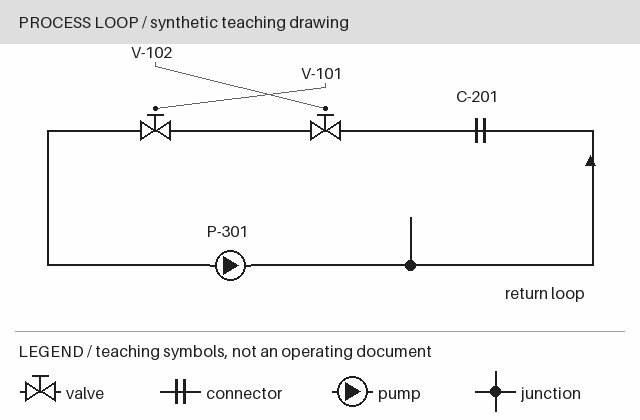

In [2]:
demo = next(e for e in examples if e.id == "d01-label-leaders")
state, assets = helpers.build_state(demo.fields)
print(
    {key: ("<content-bound image>" if key == "diagram" else value) for key, value in state.items()}
)
show_image(read_image(demo))

## The questions

A [`Noul`](https://docs.typesafe.ai/primitives) returns the probability of a proposition. Presence and unique label binding are independent judgments and go in one request. A `Box` asks only where the identified symbol lies; it goes in a dependent request. Its four edges are normalized fractions of image width and height.

A Box always returns coordinates, even for an absent target ([S10](https://docs.typesafe.ai/primitives/box)). Python therefore does not ask for a box until both propositions clear the acquisition gate. Duplicate tag labels never become permission to choose an arbitrary valve.

In [3]:
for name, question in helpers.build_questions().items():
    print(name, question.to_dict())
print("Dependent question:", helpers.build_box_question()["component"].to_dict())

present {'type': 'noul', 'instructions': 'At least one process symbol of target_kind is visibly linked to target_label in diagram. A partly clipped symbol can be present. Legend samples, free text, and labels linked to another kind of symbol do not count.', 'criteria': None}
unique {'type': 'noul', 'instructions': 'Exactly one process symbol of target_kind is unambiguously linked to target_label in diagram. Follow leader endpoints, not nearest text; duplicate labels or uncertain bindings make this proposition false.', 'criteria': None}
Dependent question: {'type': 'box', 'instructions': 'Enclose the single process symbol of target_kind linked to target_label in diagram. Use its symbol body only, including valve handle when shown; exclude text, label leaders, and long connecting pipes. Return normalized edges.'}


## One answer up close

We show the typed answers before any aggregate. The [confidence](../../docs/glossary.md#confidence) of a Noul is the derived certainty `abs(2*p - 1)`; a Box supplies its own confidence, which may be missing. These are different quantities, and the common gate below is only a policy tuned on this small synthetic sample.

The demonstration uses the predeclared acquisition floor of 0.4. Validation will choose the stricter final gate. A displayed demo rectangle is illustrative and is not a final accepted action.

Noul: 0.98 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Noul: 0.97 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Box: normalized coordinates (confidence 0.95)
  top=0.27, bottom=0.34, left=0.22, right=0.27
Provenance: synthetic
Normalized box: {'top': 0.26904761904761904, 'bottom': 0.3380952380952381, 'left': 0.2171875, 'right': 0.26875}
Pixel bounds: (139, 113, 172, 142)


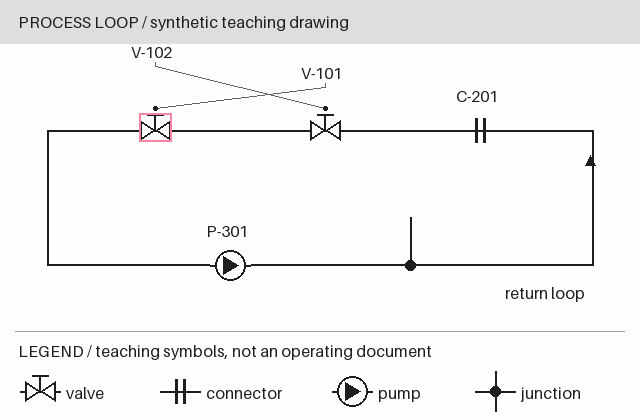

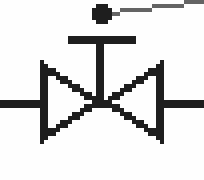

In [4]:
traces[demo.id] = helpers.collect(demo.fields, backend)
demo_trace = traces[demo.id]
show_answer(demo_trace.first["present"])
show_answer(demo_trace.first["unique"])
if demo_trace.second is not None:
    show_answer(demo_trace.second["component"])
    demo_box = demo_trace.second["component"].box
    print("Normalized box:", dict(demo_box))
    print("Pixel bounds:", normalized_to_pixels(demo_box, 640, 420))
    show_image(draw_boxes(read_image(demo), {"": demo_box}))
    crop = crop_box(read_image(demo), demo_box, expand=0.25)
    show_image(crop.resize((crop.width * 4, crop.height * 4), Image.Resampling.NEAREST))

## Python's part

The [confidence gate](../../docs/glossary.md#confidence-gate) is a threshold that Python checks before accepting an answer. `collect` has a two-request ceiling: one batched presence/binding request, then at most one dependent Box request. There is no retry loop in this recipe; live transport retries remain inside the backend's budget.

`decide` requires confident agreement between presence and uniqueness. Two confident negative propositions give a final **absent** answer; contradictory or uncertain propositions go to review. A box also needs finite normalized positive-area edges, supplied confidence, area at most 15% of the page, and no edge touching the image boundary. These checks are program rules, not guarantees that the selected symbol is correct. In particular, confidently choosing the wrong valve can pass all of them.

An `ActionLog` stores only simulated annotation coordinates. A `ReviewQueue` stores deferred lookups. Absence creates neither an annotation nor an equipment action.

Duplicate-tag decision: Outcome(status='review', box=None, reason='presence or unique binding unresolved')
Requests for duplicate-tag demo: 1
Review queue: [{'id': 0, 'item': {'diagram': 'd02-duplicate'}, 'reason': 'presence or unique binding unresolved', 'answer': None, 'step': None, 'status': 'pending', 'resolution': None}]


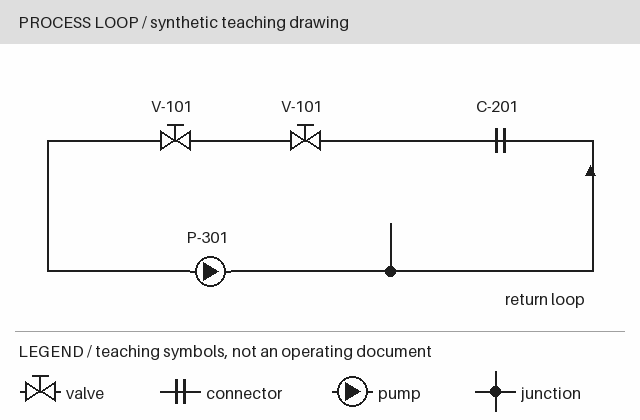

In [5]:
duplicate = next(e for e in examples if e.id == "d02-duplicate")
traces[duplicate.id] = helpers.collect(duplicate.fields, backend)
duplicate_outcome = helpers.decide(traces[duplicate.id], helpers.ACQUISITION_FLOOR)
helpers.simulate(duplicate.id, duplicate_outcome, (640, 420), actions, reviews)
print("Duplicate-tag decision:", duplicate_outcome)
print("Requests for duplicate-tag demo:", traces[duplicate.id].requests)
print("Review queue:", reviews.to_dicts())
show_image(read_image(duplicate))

## Evaluation

A [gold label](../../docs/glossary.md#gold-label) is the authored expected outcome and, when uniquely locatable, its symbol-body rectangle. The readable rationales are in `fixtures/labels.jsonl`. Intersection-over-union (**IoU**) is the intersection area divided by the union area; IoU at least 0.5 counts as the right localization. Absent targets need a final absent answer. Duplicated or clipped targets require review and cannot count as answered.

[Coverage](../../docs/glossary.md#coverage) is the fraction given a final located/absent answer. [Accuracy](../../docs/glossary.md#accuracy) is the fraction of those answers correct, and [risk](../../docs/glossary.md#risk) is its complement. We use `evaluate_outcomes` on actual decisions, so review never masquerades as coverage.

Selection maximizes coverage subject to at least 0.9 validation accepted accuracy. Candidates are the observed minimum of presence certainty, uniqueness certainty, and supplied Box confidence, for validation traces that pass all unconditional rules at the 0.4 acquisition floor. Missing confidence and clipped or ambiguous targets are excluded from this candidate pool, but remain in every full-policy denominator. The selected gate is frozen before collecting test answers.

N=12; frozen threshold=0.7800 (validation selection step) (pipeline check, not a Jev result)
Validation full policy: {'N': 12, 'answered': 8, 'review': 4, 'coverage': 0.6667, 'accuracy': 1.0, 'risk': 0.0, 'localization_N': 8, 'resolved_mean_iou': 1.0, 'resolved_misses': 0, 'absent_N': 2, 'false_positive_absence': 0, 'present_N': 8, 'present_unlocalized_including_review': 2, 'present_wrong_box': 0, 'required_review_N': 2, 'required_review_accepted': 0} (validation selection step) (pipeline check, not a Jev result)
N=12; plotted thresholds=[0.65, 0.78, 0.83, 0.88, 0.9, 0.92, 0.94]; coverage=[0.75, 0.6667, 0.5833, 0.5, 0.4167, 0.3333, 0.1667]; accuracy=[0.8889, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0] (validation selection step) (pipeline check, not a Jev result)


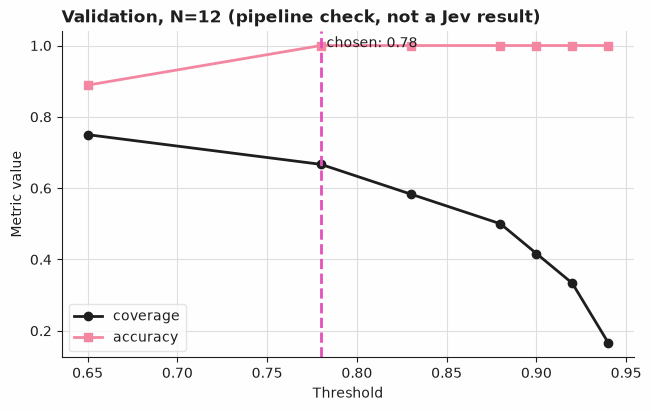

In [6]:
validation = select_split(examples, "validation")
for example in validation:
    traces[example.id] = helpers.collect(example.fields, backend)
validation_traces = [traces[e.id] for e in validation]
validation_gold = [labels[e.id] for e in validation]
threshold = helpers.choose_threshold(validation_traces, validation_gold)
validation_outcomes = [helpers.decide(t, threshold) for t in validation_traces]
print(f"N={len(validation)}; frozen threshold={threshold:.4f}{selection}{check}")
print(
    f"Validation full policy: {helpers.summarize(validation_outcomes, validation_gold)}{selection}{check}"
)

candidates = [
    (trace, gold)
    for trace, gold in zip(validation_traces, validation_gold, strict=True)
    if helpers.score(trace) is not None
]
curve = selective_curve(
    [helpers.correct(helpers.decide(t, helpers.ACQUISITION_FLOOR), g) for t, g in candidates],
    [helpers.score(t) for t, _ in candidates],
)
thresholds = sorted(curve.thresholds.tolist())
sweep = [
    helpers.summarize([helpers.decide(t, cutoff) for t in validation_traces], validation_gold)
    for cutoff in thresholds
]
print(
    f"N={len(validation)}; plotted thresholds={[round(t, 4) for t in thresholds]}; "
    f"coverage={[r['coverage'] for r in sweep]}; accuracy={[r['accuracy'] for r in sweep]}{selection}{check}"
)
plot_threshold_sweep(
    thresholds,
    {"coverage": [r["coverage"] for r in sweep], "accuracy": [r["accuracy"] for r in sweep]},
    chosen=threshold,
    title=f"Validation, N={len(validation)}{check}",
)

### A deterministic baseline on the same pixels

The baseline is a small computer-vision rule: it searches for exact binary templates of horizontal valve, flange, or pump glyphs, recognizes the requested tag using its rasterized text template, and accepts one match only when the tag occupies a small expected region above the symbol. It receives the image and the same requested tag, with no annotation metadata or fixture identifiers. Canonical glyphs and font are public assumptions of this authored drawing family.

This is a useful baseline for a controlled export format. It is brittle to font changes, scale, rotation, and label leaders that do not follow its layout convention. A production computer-vision baseline would need text recognition, rotation/scale handling, and leader tracing, evaluated on independently sourced drawings. We freeze this baseline before test and make no claim that it represents general diagram understanding.

### Held-out comparison

The test split is reported once with the frozen policy. `localization_N` includes resolved examples with unique present or absent gold; ambiguous gold and policy reviews are excluded from that IoU denominator. `resolved_misses` counts present targets incorrectly answered absent. `present_unlocalized_including_review` additionally exposes abstention on present targets, while `present_wrong_box` counts accepted localizations below the IoU requirement. The absence denominator and its false-positive count are printed separately. These distinctions prevent abstention from making localization look artificially complete.

In [7]:
test = select_split(examples, "test")
for example in test:
    traces[example.id] = helpers.collect(example.fields, backend, threshold=threshold)
test_gold = [labels[e.id] for e in test]
test_outcomes = [helpers.decide(traces[e.id], threshold) for e in test]
baseline_outcomes = [helpers.baseline(read_image(e), e.fields["target"]) for e in test]
reports = {
    "Noul then Box": helpers.summarize(test_outcomes, test_gold),
    "pixel template + label region": helpers.summarize(baseline_outcomes, test_gold),
}
for name, report in reports.items():
    print(f"Held-out {name}: {report}{check}")
for example, outcome in zip(test, test_outcomes, strict=True):
    helpers.simulate(example.id, outcome, (640, 420), actions, reviews)
print(
    f"N={len(test)}; simulated annotation count={len(actions)}; "
    f"test review count={sum(o.status == helpers.REVIEW for o in test_outcomes)}{check}"
)
print("One simulated action:", actions.to_dicts()[0])
print("Review queue entries:", reviews.to_dicts())

Held-out Noul then Box: {'N': 12, 'answered': 8, 'review': 4, 'coverage': 0.6667, 'accuracy': 0.625, 'risk': 0.375, 'localization_N': 8, 'resolved_mean_iou': 0.6667, 'resolved_misses': 1, 'absent_N': 2, 'false_positive_absence': 1, 'present_N': 8, 'present_unlocalized_including_review': 3, 'present_wrong_box': 1, 'required_review_N': 2, 'required_review_accepted': 0} (pipeline check, not a Jev result)
Held-out pixel template + label region: {'N': 12, 'answered': 10, 'review': 2, 'coverage': 0.8333, 'accuracy': 0.7, 'risk': 0.3, 'localization_N': 9, 'resolved_mean_iou': 0.7143, 'resolved_misses': 2, 'absent_N': 2, 'false_positive_absence': 0, 'present_N': 8, 'present_unlocalized_including_review': 3, 'present_wrong_box': 0, 'required_review_N': 2, 'required_review_accepted': 1} (pipeline check, not a Jev result)
N=12; simulated annotation count=6; test review count=4 (pipeline check, not a Jev result)
One simulated action: {'seq': 0, 'kind': 'annotate_diagram', 'payload': {'diagram': 't

### A confident box can still be wrong

The following held-out example passes the frozen gate but encloses the other valve. Its label is nearer the requested text; the leader endpoint is the decisive evidence the synthetic answer misses. We display both rectangles, then retain the error in the reported metrics. The fixture set also includes a confident false absence for a visible pump and a confident connector false positive on a junction dot. Policy checks do not turn these authored probabilities into dependable perception.

Box: normalized coordinates (confidence 0.96)
  top=0.29, bottom=0.35, left=0.46, right=0.51
Provenance: synthetic
Accepted outcome: located correct: False
Left rectangle: gold V-101. Right rectangle: accepted wrong valve.


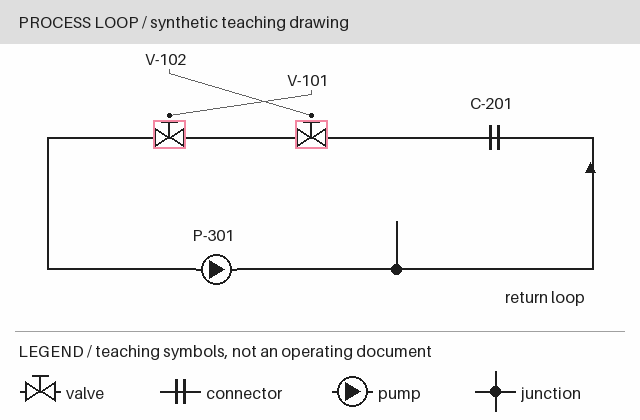

In [8]:
wrong = next(e for e in test if e.id == "t08-wrong-binding")
wrong_trace = traces[wrong.id]
wrong_outcome = test_outcomes[test.index(wrong)]
show_answer(wrong_trace.second["component"])
print(
    "Accepted outcome:",
    wrong_outcome.status,
    "correct:",
    helpers.correct(wrong_outcome, labels[wrong.id]),
)
print("Left rectangle: gold V-101. Right rectangle: accepted wrong valve.")
overlay = draw_boxes(read_image(wrong), {"": wrong_outcome.box})
show_image(draw_boxes(overlay, {"": labels[wrong.id]["box"]}))

## What was and was not measured

The cell below prints mode and N in every branch. Recorded mode additionally prints returned model and capture dates. Live mode is unrecorded exploration, not a reportable held-out measurement. Synthetic metrics check the policy and geometry only. No model quality, inference latency, token usage, or billing was measured live. Unknown values stay `None`; replay time is never inference latency.

For a deliberate recording, `helpers.record_examples` uses the shared `record` tool with `(state, questions, assets)` triples, captures first-stage answers, and constructs Box requests only for eligible targets. Use a fresh destination, a versioned live backend, and a sufficient request budget. The recorder retains actual returned model, dates, and reported usage. Do validation first, freeze the policy, and capture test once. The notebook executor always strips live settings. See [live recording](../../docs/live.md) and [offline versus live](../../docs/offline-and-live.md).

In [9]:
requests = sum(t.requests for t in traces.values())
accounting = [row for t in traces.values() for row in t.records]
if backend.mode in {"synthetic", "scripted"}:
    print(f"Mode: {backend.mode}. Not measured live: a pipeline check, not a Jev result.")
    print(f"N: 24 scored (12 validation, 12 test), 2 demos; requests={requests}{check}.")
elif backend.mode == "recorded":
    print(f"Mode: recorded; model={backend.model}; dates={backend.recorded_dates}.")
    print(f"N: 24 scored (12 validation, 12 test), 2 demos; requests={requests}.")
else:
    print(f"Mode: live; returned model={backend.model}.")
    print(f"N: 24 scored (12 validation, 12 test), 2 demos; requests={requests}.")
    print("Unrecorded exploration; no reportable held-out claim.")
print("Request accounting example:", accounting[0])
print("Latency and billed cost: None; no measured capture supplied.")

Mode: synthetic. Not measured live: a pipeline check, not a Jev result.
N: 24 scored (12 validation, 12 test), 2 demos; requests=44 (pipeline check, not a Jev result).
Request accounting example: {'model': None, 'input_tokens': None, 'output_tokens': None, 'latency_seconds': None, 'cost_usd': None, 'mode': 'synthetic'}
Latency and billed cost: None; no measured capture supplied.


## Next steps

Try a different symbol font, more crowded leaders, and rotated connector flanges on a new validation set. Keep the original test split frozen; collect a fresh independent test set for the changed task. Extend the deterministic baseline with leader tracing before comparing methods on real drawings.

[Hierarchical classification](../40-hierarchical-classification/) develops dependent stages, and [abstention and review queues](../38-abstention-and-review-queues/) explains how to evaluate deferred answers. For the underlying contracts see [Primitives (S02)](https://docs.typesafe.ai/primitives), [Confidence (S03)](https://docs.typesafe.ai/confidence), and the local [vision helpers](../../docs/vision.md).